In [1]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

data = fetch_openml("adult", version=2, as_frame=True)
X, y = data.data, (data.target == ">50K").astype(int)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

num = X.select_dtypes(include="number").columns
cat = X.select_dtypes(exclude="number").columns
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
])
clf = Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=1000))]).fit(Xtr, ytr)
pred = clf.predict(Xte)

print("overall accuracy:", (pred == yte.values).mean())
for g in Xte["sex"].unique():
    m = (Xte["sex"] == g).values
    print(g, "n =", m.sum(), "accuracy =", (pred[m] == yte.values[m]).mean())

overall accuracy: 0.8524534225073364
Male n = 9746 accuracy = 0.816540119023189
Female n = 4907 accuracy = 0.9237823517424089


In [2]:
yt = yte.values
for g in Xte["sex"].unique():
    m = (Xte["sex"] == g).values
    yg, pg = yt[m], pred[m]
    print(g,
          "base rate:", round(yg.mean(), 3),
          "selection rate:", round(pg.mean(), 3),
          "TPR:", round(pg[yg == 1].mean(), 3),
          "FPR:", round(pg[yg == 0].mean(), 3))

Male base rate: 0.304 selection rate: 0.256 TPR: 0.62 FPR: 0.097
Female base rate: 0.111 selection rate: 0.07 TPR: 0.472 FPR: 0.02


In [4]:
import numpy as np, torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

pre_fit = clf.named_steps["pre"]
dense = lambda a: a.toarray() if hasattr(a, "toarray") else a
Xtr_t = torch.tensor(dense(pre_fit.transform(Xtr)), dtype=torch.float32)
Xte_t = torch.tensor(dense(pre_fit.transform(Xte)), dtype=torch.float32)
ytr_t = torch.tensor(ytr.values, dtype=torch.float32)
yt = yte.values
is_male = (Xte["sex"] == "Male").values

def report(pred):
    print("accuracy:", round((pred == yt).mean(), 4))
    stats = {}
    for name, m in [("Male", is_male), ("Female", ~is_male)]:
        yg, pg = yt[m], pred[m]
        stats[name] = (pg.mean(), pg[yg == 1].mean(), pg[yg == 0].mean())
        print(name, "selection:", round(stats[name][0], 3),
              "TPR:", round(stats[name][1], 3), "FPR:", round(stats[name][2], 3))
    print("gaps (male - female) -> selection:", round(stats["Male"][0] - stats["Female"][0], 3),
          "TPR:", round(stats["Male"][1] - stats["Female"][1], 3),
          "FPR:", round(stats["Male"][2] - stats["Female"][2], 3))

def train_baseline(seed=0, epochs=10, bs=512, lr=0.01):
    torch.manual_seed(seed)
    model = nn.Linear(Xtr_t.shape[1], 1)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=bs, shuffle=True)
    loss_fn = nn.BCEWithLogitsLoss()
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            loss_fn(model(xb).squeeze(1), yb).backward()
            opt.step()
    return model

model = train_baseline()
with torch.no_grad():
    pred_t = (torch.sigmoid(model(Xte_t).squeeze(1)) > 0.5).int().numpy()
report(pred_t)

accuracy: 0.8512
Male selection: 0.264 TPR: 0.631 FPR: 0.104
Female selection: 0.072 TPR: 0.476 FPR: 0.022
gaps (male - female) -> selection: 0.192 TPR: 0.155 FPR: 0.083


In [ ]:
from opacus import PrivacyEngine

def train_dp(epsilon, seed=0, epochs=10, bs=512, lr=0.01, delta=1e-5, max_grad_norm=1.0):
    torch.manual_seed(seed)
    model = nn.Linear(Xtr_t.shape[1], 1)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=bs, shuffle=True)
    pe = PrivacyEngine()
    model, opt, loader = pe.make_private_with_epsilon(
        module=model, optimizer=opt, data_loader=loader,
        target_epsilon=epsilon, target_delta=delta,
        epochs=epochs, max_grad_norm=max_grad_norm)
    loss_fn = nn.BCEWithLogitsLoss()
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            loss_fn(model(xb).squeeze(1), yb).backward()
            opt.step()
    print("epsilon spent:", round(pe.get_epsilon(delta), 3))
    return model

dp_model = train_dp(epsilon=1.0)
dp_model.eval()
with torch.no_grad():
    pred_dp = (torch.sigmoid(dp_model(Xte_t).squeeze(1)) > 0.5).int().numpy()
report(pred_dp)

In [6]:
import io, warnings, pandas as pd
from contextlib import redirect_stdout
warnings.filterwarnings("ignore", category=UserWarning)

def metrics(pred):
    out = {"accuracy": (pred == yt).mean()}
    for name, m in [("M", is_male), ("F", ~is_male)]:
        yg, pg = yt[m], pred[m]
        out[f"sel_{name}"] = pg.mean()
        out[f"tpr_{name}"] = pg[yg == 1].mean()
        out[f"fpr_{name}"] = pg[yg == 0].mean()
    out["sel_gap"] = out["sel_M"] - out["sel_F"]
    out["tpr_gap"] = out["tpr_M"] - out["tpr_F"]
    out["fpr_gap"] = out["fpr_M"] - out["fpr_F"]
    return out

def predict(model):
    model.eval()
    with torch.no_grad():
        return (torch.sigmoid(model(Xte_t).squeeze(1)) > 0.5).int().numpy()

rows = []
for seed in range(10):
    rows.append({"eps": float("inf"), "seed": seed,
                 **metrics(predict(train_baseline(seed=seed)))})
    for eps in [0.1, 0.5, 1, 4, 8]:
        with redirect_stdout(io.StringIO()):
            m = train_dp(epsilon=eps, seed=seed)
        rows.append({"eps": eps, "seed": seed, **metrics(predict(m))})

df = pd.DataFrame(rows)
df.to_csv("dp_results.csv", index=False)
print(df.groupby("eps")[["accuracy", "sel_gap", "tpr_gap", "fpr_gap"]]
        .agg(["mean", "std"]).round(3))

    accuracy        sel_gap        tpr_gap        fpr_gap       
        mean    std    mean    std    mean    std    mean    std
eps                                                             
0.1    0.841  0.001   0.198  0.008   0.248  0.025   0.087  0.005
0.5    0.851  0.001   0.187  0.005   0.164  0.013   0.079  0.005
1.0    0.852  0.001   0.187  0.004   0.158  0.009   0.078  0.004
4.0    0.852  0.000   0.186  0.004   0.155  0.009   0.077  0.004
8.0    0.852  0.001   0.187  0.004   0.155  0.008   0.078  0.004
inf    0.852  0.001   0.184  0.007   0.146  0.010   0.076  0.005


In [8]:
import pandas as pd
from scipy import stats

df = pd.read_csv("dp_results.csv")
print(df.groupby("eps")[["tpr_M", "tpr_F", "sel_M", "sel_F"]].mean().round(3))

base = df[df.eps == float("inf")].set_index("seed")
for eps in [0.1, 0.5, 1.0, 4.0, 8.0]:
    d = df[df.eps == eps].set_index("seed")["tpr_gap"] - base["tpr_gap"]
    ci = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d))
    print(eps, "change in TPR gap:", round(d.mean(), 3),
          "95% CI", tuple(round(x, 3) for x in ci))

     tpr_M  tpr_F  sel_M  sel_F
eps                            
0.1  0.581  0.333  0.246  0.048
0.5  0.609  0.444  0.252  0.065
1.0  0.613  0.455  0.253  0.066
4.0  0.616  0.461  0.254  0.068
8.0  0.617  0.462  0.254  0.068
inf  0.615  0.468  0.253  0.070
0.1 change in TPR gap: 0.101 95% CI (np.float64(0.08), np.float64(0.123))
0.5 change in TPR gap: 0.018 95% CI (np.float64(0.006), np.float64(0.03))
1.0 change in TPR gap: 0.012 95% CI (np.float64(0.002), np.float64(0.022))
4.0 change in TPR gap: 0.009 95% CI (np.float64(-0.0), np.float64(0.018))
8.0 change in TPR gap: 0.009 95% CI (np.float64(0.0), np.float64(0.017))


In [9]:
from sklearn.metrics import roc_auc_score

def scores(model):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(Xte_t).squeeze(1)).numpy()

rows2 = []
for seed in range(10):
    runs = [(float("inf"), train_baseline(seed=seed))]
    for eps in [0.1, 1.0]:
        with redirect_stdout(io.StringIO()):
            runs.append((eps, train_dp(epsilon=eps, seed=seed)))
    for eps, m in runs:
        s = scores(m)
        rows2.append({"eps": eps, "seed": seed,
                      "auc_M": roc_auc_score(yt[is_male], s[is_male]),
                      "auc_F": roc_auc_score(yt[~is_male], s[~is_male])})
df2 = pd.DataFrame(rows2)
df2.to_csv("dp_auc.csv", index=False)
print(df2.groupby("eps")[["auc_M", "auc_F"]].agg(["mean", "std"]).round(3))

     auc_M         auc_F       
      mean    std   mean    std
eps                            
0.1  0.867  0.002  0.918  0.003
1.0  0.877  0.000  0.928  0.001
inf  0.880  0.000  0.929  0.000


In [10]:
rows3 = []
for seed in range(10):
    base = train_baseline(seed=seed)
    sb = scores(base)
    rate = (sb > 0.5).mean()
    models = [(float("inf"), base)]
    with redirect_stdout(io.StringIO()):
        models.append((0.1, train_dp(epsilon=0.1, seed=seed)))
    for eps, m in models:
        s = scores(m)
        t = np.quantile(s, 1 - rate)
        p = (s > t).astype(int)
        rows3.append({"eps": eps, "seed": seed,
                      "mean_score_M": s[is_male].mean(),
                      "mean_score_F": s[~is_male].mean(),
                      "tpr_M_matched": p[is_male][yt[is_male] == 1].mean(),
                      "tpr_F_matched": p[~is_male][yt[~is_male] == 1].mean()})
df3 = pd.DataFrame(rows3)
df3["tpr_gap_matched"] = df3.tpr_M_matched - df3.tpr_F_matched
df3.to_csv("dp_matched.csv", index=False)
print(df3.groupby("eps")[["mean_score_M", "mean_score_F",
      "tpr_M_matched", "tpr_F_matched", "tpr_gap_matched"]].agg(["mean", "std"]).round(3))

    mean_score_M        mean_score_F        tpr_M_matched         \
            mean    std         mean    std          mean    std   
eps                                                                
0.1        0.275  0.007        0.072  0.005         0.605  0.011   
inf        0.304  0.006        0.105  0.002         0.615  0.012   

    tpr_F_matched        tpr_gap_matched        
             mean    std            mean   std  
eps                                             
0.1         0.366  0.032           0.239  0.03  
inf         0.468  0.007           0.146  0.01  


In [11]:
rows4 = []
for seed in range(10):
    base = train_baseline(seed=seed)
    rate = (scores(base) > 0.5).mean()
    for gn in [0.1, 1.0, 5.0]:
        with redirect_stdout(io.StringIO()):
            m = train_dp(epsilon=0.1, seed=seed, max_grad_norm=gn)
        s = scores(m)
        p = (s > np.quantile(s, 1 - rate)).astype(int)
        rows4.append({"clip": gn, "seed": seed,
            "mean_score_M": s[is_male].mean(), "mean_score_F": s[~is_male].mean(),
            "tpr_gap_matched": p[is_male][yt[is_male] == 1].mean()
                               - p[~is_male][yt[~is_male] == 1].mean(),
            "auc_M": roc_auc_score(yt[is_male], s[is_male]),
            "auc_F": roc_auc_score(yt[~is_male], s[~is_male])})
df4 = pd.DataFrame(rows4)
df4.to_csv("dp_clip_sensitivity.csv", index=False)
print(df4.groupby("clip")[["mean_score_M", "mean_score_F", "tpr_gap_matched",
      "auc_M", "auc_F"]].agg(["mean", "std"]).round(3))

     mean_score_M        mean_score_F        tpr_gap_matched         auc_M  \
             mean    std         mean    std            mean    std   mean   
clip                                                                         
0.1         0.225  0.005        0.045  0.003           0.258  0.018  0.864   
1.0         0.275  0.007        0.072  0.005           0.239  0.030  0.867   
5.0         0.307  0.010        0.103  0.010           0.292  0.052  0.860   

             auc_F         
        std   mean    std  
clip                       
0.1   0.001  0.909  0.003  
1.0   0.002  0.918  0.003  
5.0   0.003  0.911  0.006  


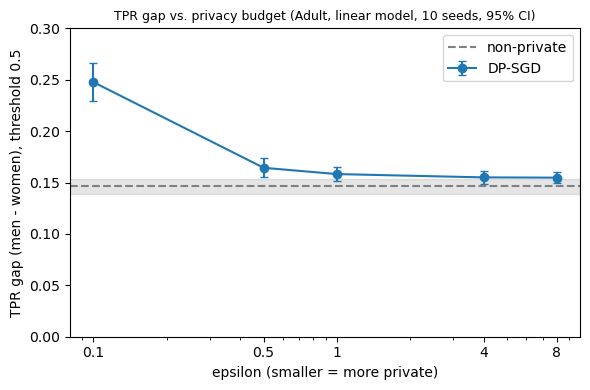

In [19]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
from matplotlib.ticker import NullFormatter

df = pd.read_csv("dp_results.csv")
g = df.groupby("eps")["tpr_gap"]
mean, ci = g.mean(), g.sem() * stats.t.ppf(0.975, 9)

eps_vals = [0.1, 0.5, 1.0, 4.0, 8.0]
base = float("inf")

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(eps_vals, mean[eps_vals], yerr=ci[eps_vals], fmt="o-", capsize=3, label="DP-SGD")
ax.axhline(mean[base], color="gray", ls="--", label="non-private")
ax.axhspan(mean[base] - ci[base], mean[base] + ci[base], color="gray", alpha=0.2)
ax.set_xscale("log")
ax.set_xticks([0.1, 0.5, 1, 4, 8])
ax.set_xticklabels(["0.1", "0.5", "1", "4", "8"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_ylim(0, 0.3)
ax.set_xlabel("epsilon (smaller = more private)")
ax.set_ylabel("TPR gap (men - women), threshold 0.5")
ax.set_title("TPR gap vs. privacy budget (Adult, linear model, 10 seeds, 95% CI)", fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig("tpr_gap_vs_epsilon.png", dpi=200)
plt.show()

In [21]:
def train_clip_only(clip, seed=0, epochs=10, bs=512, lr=0.01):
    torch.manual_seed(seed)
    model = nn.Linear(Xtr_t.shape[1], 1)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=bs, shuffle=True)
    pe = PrivacyEngine()
    model, opt, loader = pe.make_private(module=model, optimizer=opt, data_loader=loader,
                                         noise_multiplier=0.0, max_grad_norm=clip)
    loss_fn = nn.BCEWithLogitsLoss()
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            loss_fn(model(xb).squeeze(1), yb).backward()
            opt.step()
    return model

rows5 = []
for seed in range(10):
    rate = (scores(train_baseline(seed=seed)) > 0.5).mean()
    for clip in [1e6, 5.0, 1.0, 0.1]:
        m = train_clip_only(clip, seed=seed)
        s = scores(m)
        p = (s > np.quantile(s, 1 - rate)).astype(int)
        rows5.append({"clip": clip, "seed": seed,
            "mean_score_M": s[is_male].mean(), "mean_score_F": s[~is_male].mean(),
            "tpr_gap_matched": p[is_male][yt[is_male] == 1].mean()
                               - p[~is_male][yt[~is_male] == 1].mean(),
            "auc_M": roc_auc_score(yt[is_male], s[is_male]),
            "auc_F": roc_auc_score(yt[~is_male], s[~is_male])})
df5 = pd.DataFrame(rows5)
df5.to_csv("dp_clip_only.csv", index=False)
print(df5.groupby("clip")[["mean_score_M", "mean_score_F", "tpr_gap_matched",
      "auc_M", "auc_F"]].agg(["mean", "std"]).round(3))

          mean_score_M        mean_score_F        tpr_gap_matched         \
                  mean    std         mean    std            mean    std   
clip                                                                       
0.1              0.240  0.003        0.064  0.001           0.158  0.008   
1.0              0.279  0.006        0.084  0.002           0.158  0.010   
5.0              0.305  0.006        0.105  0.003           0.145  0.011   
1000000.0        0.305  0.006        0.105  0.003           0.145  0.010   

           auc_M       auc_F       
            mean  std   mean  std  
clip                               
0.1        0.873  0.0  0.925  0.0  
1.0        0.878  0.0  0.929  0.0  
5.0        0.880  0.0  0.928  0.0  
1000000.0  0.880  0.0  0.928  0.0  


In [20]:
print("rows total:", len(X))
print("train / test:", len(Xtr), len(Xte))
print("train by sex:", Xtr["sex"].value_counts().to_dict())
print("test by sex:", Xte["sex"].value_counts().to_dict())
print("train positives by sex:", ytr.groupby(Xtr["sex"], observed=True).sum().to_dict())
print("test positives by sex:", yte.groupby(Xte["sex"], observed=True).sum().to_dict())
print("feature matrix after preprocessing:", Xtr_t.shape)

rows total: 48842
train / test: 34189 14653
train by sex: {'Male': 22904, 'Female': 11285}
test by sex: {'Male': 9746, 'Female': 4907}
train positives by sex: {'Female': 1225, 'Male': 6956}
test positives by sex: {'Female': 544, 'Male': 2962}
feature matrix after preprocessing: torch.Size([34189, 105])


In [22]:
for eps in [0.1, 0.5, 1, 4, 8]:
    torch.manual_seed(0)
    model = nn.Linear(Xtr_t.shape[1], 1)
    opt = torch.optim.Adam(model.parameters(), lr=0.01)
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=512, shuffle=True)
    pe = PrivacyEngine()
    model, opt, loader = pe.make_private_with_epsilon(
        module=model, optimizer=opt, data_loader=loader,
        target_epsilon=eps, target_delta=1e-5, epochs=10, max_grad_norm=1.0)
    loss_fn = nn.BCEWithLogitsLoss()
    steps = 0
    for _ in range(10):
        for xb, yb in loader:
            opt.zero_grad()
            loss_fn(model(xb).squeeze(1), yb).backward()
            opt.step()
            steps += 1
    print(eps, "| noise multiplier:", round(opt.noise_multiplier, 3),
          "| sample rate:", round(loader.sample_rate, 4),
          "| steps:", steps,
          "| accountant:", pe.accountant.mechanism(),
          "| epsilon spent:", round(pe.get_epsilon(1e-5), 3),
          "| sampler:", type(loader.batch_sampler).__name__)

0.1 | noise multiplier: 13.75 | sample rate: 0.0149 | steps: 670 | accountant: prv | epsilon spent: 0.096 | sampler: UniformWithReplacementSampler
0.5 | noise multiplier: 2.969 | sample rate: 0.0149 | steps: 670 | accountant: prv | epsilon spent: 0.49 | sampler: UniformWithReplacementSampler
1 | noise multiplier: 1.68 | sample rate: 0.0149 | steps: 670 | accountant: prv | epsilon spent: 0.994 | sampler: UniformWithReplacementSampler
4 | noise multiplier: 0.798 | sample rate: 0.0149 | steps: 670 | accountant: prv | epsilon spent: 3.995 | sampler: UniformWithReplacementSampler
8 | noise multiplier: 0.624 | sample rate: 0.0149 | steps: 670 | accountant: prv | epsilon spent: 7.991 | sampler: UniformWithReplacementSampler


In [23]:
def twice(fn):
    a = scores(fn())
    b = scores(fn())
    return float(np.abs(a - b).max())

print("baseline max |diff|:", twice(lambda: train_baseline(seed=3)))
print("dp eps=1  max |diff|:", twice(lambda: train_dp(epsilon=1.0, seed=3)))
print("dp eps=0.1 max |diff|:", twice(lambda: train_dp(epsilon=0.1, seed=3)))

baseline max |diff|: 0.0
epsilon spent: 0.994
epsilon spent: 0.994
dp eps=1  max |diff|: 0.0
epsilon spent: 0.096
epsilon spent: 0.096
dp eps=0.1 max |diff|: 0.0


In [24]:
from sklearn.base import clone

def make_split(split_seed):
    Xtr_, Xte_, ytr_, yte_ = train_test_split(X, y, test_size=0.3,
                                              random_state=split_seed, stratify=y)
    pre_ = clone(pre).fit(Xtr_)
    to_t = lambda a: torch.tensor(dense(a), dtype=torch.float32)
    return (to_t(pre_.transform(Xtr_)), torch.tensor(ytr_.values, dtype=torch.float32),
            to_t(pre_.transform(Xte_)), yte_.values, (Xte_["sex"] == "Male").values)

def fit_local(Xt, yt_t, eps, seed, epochs=10, bs=512, lr=0.01, clip=1.0, delta=1e-5):
    torch.manual_seed(seed)
    model = nn.Linear(Xt.shape[1], 1)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(Xt, yt_t), batch_size=bs, shuffle=True)
    if eps is not None:
        pe = PrivacyEngine()
        model, opt, loader = pe.make_private_with_epsilon(
            module=model, optimizer=opt, data_loader=loader,
            target_epsilon=eps, target_delta=delta, epochs=epochs, max_grad_norm=clip)
    loss_fn = nn.BCEWithLogitsLoss()
    for _ in range(epochs):
        for xb, yb in loader:
            opt.zero_grad()
            loss_fn(model(xb).squeeze(1), yb).backward()
            opt.step()
    model.eval()
    return model

def score_local(model, Xe):
    with torch.no_grad():
        return torch.sigmoid(model(Xe).squeeze(1)).numpy()

rows6 = []
for split in range(1, 6):
    Xt, yt_t, Xe, ye, male = make_split(split)
    for seed in range(3):
        base_model = fit_local(Xt, yt_t, None, seed)
        rate = (score_local(base_model, Xe) > 0.5).mean()
        for eps in [None, 0.1, 0.5, 1.0, 8.0]:
            m = base_model if eps is None else fit_local(Xt, yt_t, eps, seed)
            s = score_local(m, Xe)
            p = (s > 0.5).astype(int)
            pm = (s > np.quantile(s, 1 - rate)).astype(int)
            pos_m, pos_f = male & (ye == 1), ~male & (ye == 1)
            rows6.append({"split": split, "seed": seed,
                          "eps": float("inf") if eps is None else eps,
                          "accuracy": (p == ye).mean(),
                          "tpr_gap": p[pos_m].mean() - p[pos_f].mean(),
                          "tpr_gap_matched": pm[pos_m].mean() - pm[pos_f].mean(),
                          "auc_M": roc_auc_score(ye[male], s[male]),
                          "auc_F": roc_auc_score(ye[~male], s[~male])})

df6 = pd.DataFrame(rows6)
df6.to_csv("dp_multisplit.csv", index=False)
base = df6[df6.eps == float("inf")].set_index(["split", "seed"])
print("non-private TPR gap by split:", base["tpr_gap"].groupby("split").mean().round(3).tolist())
for col in ["tpr_gap", "tpr_gap_matched"]:
    for eps in [0.1, 0.5, 1.0, 8.0]:
        d = (df6[df6.eps == eps].set_index(["split", "seed"])[col] - base[col]).groupby("split").mean()
        ci = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d))
        print(col, eps, "mean change", round(d.mean(), 3),
              "CI across splits", tuple(round(float(x), 3) for x in ci),
              "per split", d.round(3).tolist())

non-private TPR gap by split: [0.164, 0.087, 0.106, 0.137, 0.155]
tpr_gap 0.1 mean change 0.067 CI across splits (0.041, 0.093) per split [0.059, 0.064, 0.093, 0.079, 0.038]
tpr_gap 0.5 mean change 0.008 CI across splits (-0.009, 0.026) per split [-0.003, 0.007, 0.025, 0.02, -0.007]
tpr_gap 1.0 mean change 0.005 CI across splits (-0.012, 0.023) per split [-0.004, 0.005, 0.022, 0.016, -0.012]
tpr_gap 8.0 mean change 0.004 CI across splits (-0.015, 0.023) per split [-0.005, 0.009, 0.022, 0.013, -0.017]
tpr_gap_matched 0.1 mean change 0.064 CI across splits (0.043, 0.085) per split [0.057, 0.062, 0.087, 0.072, 0.042]
tpr_gap_matched 0.5 mean change 0.009 CI across splits (-0.005, 0.023) per split [-0.002, 0.009, 0.024, 0.016, -0.001]
tpr_gap_matched 1.0 mean change 0.007 CI across splits (-0.008, 0.022) per split [-0.004, 0.009, 0.02, 0.017, -0.006]
tpr_gap_matched 8.0 mean change 0.005 CI across splits (-0.011, 0.02) per split [-0.005, 0.011, 0.016, 0.013, -0.012]


In [25]:
d6 = pd.read_csv("dp_multisplit.csv")
b = d6[d6.eps == float("inf")].set_index(["split", "seed"])
for eps in [0.1, 1.0]:
    t = d6[d6.eps == eps].set_index(["split", "seed"])
    chg = (t[["accuracy", "auc_M", "auc_F"]] - b[["accuracy", "auc_M", "auc_F"]]).groupby("split").mean()
    print("epsilon", eps)
    print(chg.round(3))
    print("mean:", chg.mean().round(3).to_dict())

epsilon 0.1
       accuracy  auc_M  auc_F
split                        
1        -0.011 -0.011 -0.011
2        -0.008 -0.013 -0.013
3        -0.007 -0.011 -0.009
4        -0.007 -0.010 -0.013
5        -0.006 -0.011 -0.011
mean: {'accuracy': -0.008, 'auc_M': -0.011, 'auc_F': -0.012}
epsilon 1.0
       accuracy  auc_M  auc_F
split                        
1        -0.001 -0.003 -0.003
2        -0.000 -0.003 -0.003
3        -0.001 -0.003 -0.001
4        -0.000 -0.002 -0.002
5        -0.000 -0.003 -0.002
mean: {'accuracy': -0.001, 'auc_M': -0.003, 'auc_F': -0.002}


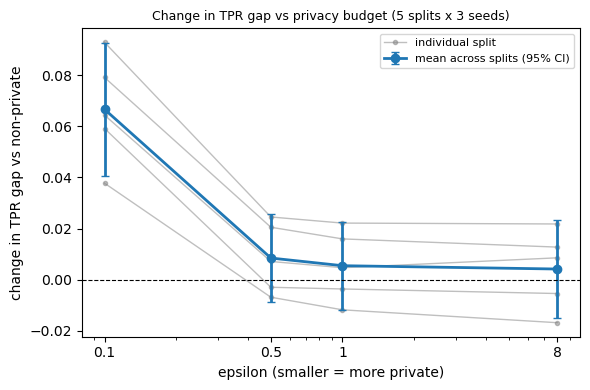

In [26]:
d6 = pd.read_csv("dp_multisplit.csv")
b = d6[d6.eps == float("inf")].set_index(["split", "seed"])["tpr_gap"]
eps_vals = [0.1, 0.5, 1.0, 8.0]
chg = {e: (d6[d6.eps == e].set_index(["split", "seed"])["tpr_gap"] - b).groupby("split").mean()
       for e in eps_vals}

fig, ax = plt.subplots(figsize=(6, 4))
for s in range(1, 6):
    ax.plot(eps_vals, [chg[e][s] for e in eps_vals], color="gray", alpha=0.5, lw=1,
            marker="o", ms=3, label="individual split" if s == 1 else None)
means = [chg[e].mean() for e in eps_vals]
cis = [chg[e].sem() * stats.t.ppf(0.975, 4) for e in eps_vals]
ax.errorbar(eps_vals, means, yerr=cis, fmt="o-", color="C0", capsize=3, lw=2,
            label="mean across splits (95% CI)")
ax.axhline(0, color="black", lw=0.8, ls="--")
ax.set_xscale("log")
ax.set_xticks(eps_vals)
ax.set_xticklabels(["0.1", "0.5", "1", "8"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("epsilon (smaller = more private)")
ax.set_ylabel("change in TPR gap vs non-private")
ax.set_title("Change in TPR gap vs privacy budget (5 splits x 3 seeds)", fontsize=9)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("tpr_gap_change_multisplit.png", dpi=200)
plt.show()

In [27]:
import sys, sklearn, pandas, numpy, scipy, matplotlib, torch, opacus
print("python", sys.version.split()[0])
for m in [sklearn, pandas, numpy, scipy, matplotlib, torch, opacus]:
    print(m.__name__, m.__version__)

python 3.13.9
sklearn 1.7.2
pandas 2.3.3
numpy 2.3.5
scipy 1.16.3
matplotlib 3.10.6
torch 2.14.1+cpu
opacus 1.6.0
